# Task 2 · Part 2 — From baseline models to structured extraction

**Guiding question:** Can scanned documents and audio interviews be converted into a structured, searchable text archive?

Part 1 produced the corpus and a first extraction. This notebook asks how good that extraction is, and at what cost. It (1) fixes an evaluation sample of 10 documents and 10 clips with manual reference transcriptions, (2) measures the baseline models with CER and WER, (3) compares each baseline with an alternative model on exactly the same files, (4) extracts structured fields with a large language model and audits them by hand, and (5) closes with a model choice for a real setting.

| Component | Models compared on the same sample |
|---|---|
| **Documents (CER)** | PaddleOCR 3.7 default configuration (baseline) · PaddleOCR PP-OCRv5 mobile (Part 1 configuration) · Gemini vision model (cloud VLM) |
| **Audio (WER, latency)** | faster-whisper `small`, CPU, VAD (baseline, Part 1) · Qwen3-ASR 0.6B (Session 13) |
| **Structured extraction** | Gemini (JSON output) + human audit of 20 random extractions |

**Evaluation rules.** The sample was fixed before any metric was computed and was not changed afterwards. No parameter was tuned on these files. References were transcribed manually. References and model outputs are pseudonymized with the same table and normalized with the same function (`voz.normalizar`, Session 13): lower case, no punctuation, accents kept. Speaker labels such as `[HABLANTE_1]` are removed before computing WER because they are not spoken words.

## 1. Setup

In [4]:
import sys

# Gemini SDK and .env reader (not included in the course's docai/audio groups).
!uv pip install google-genai python-dotenv --python "{sys.executable}"

Using Python 3.12.14 environment at: c:\Users\Ana Karen\Documents\GitHub\Data-Science-Python\.venv
Checked 2 packages in 487ms


In [5]:
import json
import os
import re
import time
from datetime import date
from pathlib import Path

import jiwer
import pandas as pd
from dotenv import load_dotenv

# Reuse the Session 13 helpers: audio loading, ASR models and text normalization.
sys.path.append(r"C:\Users\Ana Karen\Documents\GitHub\Data-Science-Python\sessions\13-audio-a-texto")
import voz

RAW = Path("datos/raw")
DATOS = Path("datos")
REFERENCIAS = RAW / "referencias"
EJEMPLOS = DATOS / "ejemplos"
EJEMPLOS.mkdir(exist_ok=True)

documentos = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)

# Evaluation sample, fixed BEFORE computing any metric: the three document types
# and clips from all six interviews, including a noisy recording (interview 3).
MUESTRA_DOCS = ["doc_005",                                              # printed
                "doc_012", "doc_013", "doc_015", "doc_016",             # photographed
                "doc_017", "doc_018", "doc_019", "doc_023", "doc_024"]  # handwritten
MUESTRA_CLIPS = ["clip_001", "clip_006", "clip_013", "clip_025", "clip_030",
                 "clip_037", "clip_042", "clip_049", "clip_061", "clip_066"]

faltan = [i for i in MUESTRA_DOCS + MUESTRA_CLIPS if not (REFERENCIAS / f"{i}.txt").exists()]
print(f"Documents: {len(documentos)} | clips: {len(transcripciones)}")
print(f"Manual references missing ({len(faltan)}):", faltan)

Documents: 25 | clips: 70
Manual references missing (0): []


## 2. Manual references

The 20 files were transcribed manually, word for word, including fillers and spelling mistakes. Two kinds of annotations written during transcription are removed because they are not part of the text or the speech: speaker labels (`Persona 1:`) and the mark `(inescuchable)` for unintelligible passages. References are then pseudonymized with the table built in Part 1. Names that appear only in the references are detected with the same NER model and added to that table, so that no real name is published. The pattern for mobile numbers was also extended to numbers written with the `+51` prefix, which Part 1 missed, and the corpus texts are pseudonymized again with the updated rules.

In [6]:
from transformers import pipeline

seudonimos = json.loads((RAW / "seudonimos.json").read_text(encoding="utf-8"))
ner = pipeline("token-classification", model="mrm8488/bert-spanish-cased-finetuned-ner",
               aggregation_strategy="simple", device=-1)

# Same rules as in Part 1.
NO_SON_NOMBRES = {"Ministro de Justicia", "Fiscal de la Nación", "Derechos Humanos", "Ministro",
                  "Ramón Castilla Marquisado", "Prin", "Octa", "Arca"}
PATRONES = {
    "[CORREO]": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "[TELEFONO]": r"(?<!\d)(?:\+?51[\s-]?)?9\d{2}[\s-]?\d{3}[\s-]?\d{3}(?!\d)",
    "[DNI]": r"(?<!\d)\d{8}(?!\d)",
}


def limpiar_nombre(nombre: str) -> str:
    # Remove sub-word markers ('##') and a leading word fragment left by the tokenizer.
    partes = nombre.replace("##", "").strip().split()
    if len(partes) > 1 and partes[0][0].islower():
        partes = partes[1:]
    return " ".join(partes)


def personas_en(texto: str, tam: int = 80) -> set[str]:
    # Person names detected by the NER model, in chunks of 80 words (the model accepts 512 tokens).
    palabras = texto.split()
    nombres = set()
    for i in range(0, len(palabras), tam):
        for ent in ner(" ".join(palabras[i:i + tam])):
            if ent["entity_group"] == "PER" and ent["score"] > 0.8:
                nombre = limpiar_nombre(ent["word"])
                if (len(nombre) > 3 and nombre not in NO_SON_NOMBRES
                        and re.fullmatch(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ .'-]+", nombre)):
                    nombres.add(nombre)
    return nombres


def seudonimizar(texto: str) -> str:
    # Replace names (case-sensitive, longest first) and direct identifiers.
    for nombre in sorted(seudonimos, key=len, reverse=True):
        texto = re.sub(rf"\b{re.escape(nombre)}\b", seudonimos[nombre], texto)
    for alias, patron in PATRONES.items():
        texto = re.sub(patron, alias, texto)
    return texto


def limpiar_referencia(texto: str) -> str:
    # Remove annotations written by the transcriber that are not part of the text or speech.
    texto = re.sub(r"(?i)^\s*(doc|clip)[ _]?\d+\s*", "", texto)          # optional header line
    texto = re.sub(r"(?im)^\s*persona\s*\d+\s*:\s*", "", texto)          # speaker labels
    texto = re.sub(r"(?i)\((?:inescuchable|inaudible)\)", " ", texto)    # unintelligible marks
    return " ".join(texto.split())


referencias = {}
for id_ in MUESTRA_DOCS + MUESTRA_CLIPS:
    texto = limpiar_referencia((REFERENCIAS / f"{id_}.txt").read_text(encoding="utf-8"))
    for nombre in personas_en(texto) - set(seudonimos):
        seudonimos[nombre] = f"[PERSONA_{len(seudonimos) + 1}]"
    referencias[id_] = texto

referencias = {id_: seudonimizar(texto) for id_, texto in referencias.items()}
(RAW / "seudonimos.json").write_text(json.dumps(seudonimos, ensure_ascii=False, indent=1), encoding="utf-8")

# The phone pattern now also covers numbers written with the +51 prefix (missed in Part 1),
# so the published corpus texts are pseudonymized again with the updated table and patterns.
documentos["texto_ocr"] = documentos["texto_ocr"].map(seudonimizar)
transcripciones["texto_asr"] = transcripciones["texto_asr"].map(seudonimizar)
documentos["texto_referencia"] = documentos["id"].map(referencias).fillna("")
transcripciones["texto_referencia"] = transcripciones["id"].map(referencias).fillna("")
documentos.to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")

palabras_ref = pd.Series({i: len(t.split()) for i, t in referencias.items()})
print(f"References stored: {(documentos['texto_referencia'] != '').sum()} documents, "
      f"{(transcripciones['texto_referencia'] != '').sum()} clips")
print(f"Words transcribed by hand: {palabras_ref[MUESTRA_DOCS].sum()} (documents), "
      f"{palabras_ref[MUESTRA_CLIPS].sum()} (audio)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: mrm8488/bert-spanish-cased-finetuned-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


References stored: 10 documents, 10 clips
Words transcribed by hand: 2134 (documents), 696 (audio)


## 3. Metrics

**CER** (character error rate) and **WER** (word error rate) count the substitutions, deletions and insertions needed to turn the model output into the reference, divided by the length of the reference. Zero is a perfect transcription, and values above one are possible when a model adds a lot of text. Per-file scores are reported together with a pooled score for each model, computed over the ten files at once (`jiwer` over the lists), so that long files weigh more than short ones.

In [7]:
def preparar(texto: str) -> str:
    # Remove speaker labels and apply the Session 13 normalization.
    return voz.normalizar(re.sub(r"\[HABLANTE_\d+\]", " ", texto))


def cer(referencia: str, hipotesis: str) -> float:
    return jiwer.cer(preparar(referencia), preparar(hipotesis) or "∅")


def wer(referencia: str, hipotesis: str) -> float:
    return jiwer.wer(preparar(referencia), preparar(hipotesis) or "∅")


def cer_global(ids, textos):
    return jiwer.cer([preparar(referencias[i]) for i in ids], [preparar(textos[i]) or "∅" for i in ids])


def wer_global(ids, textos):
    return jiwer.wer([preparar(referencias[i]) for i in ids], [preparar(textos[i]) or "∅" for i in ids])


muestra_docs = documentos.set_index("id").loc[MUESTRA_DOCS]
muestra_clips = transcripciones.set_index("id").loc[MUESTRA_CLIPS]
resultados_ocr = []   # one row per (document, model)
resultados_asr = []   # one row per (clip, model)

## 4. Documents: baseline and alternative OCR models

Three readers are compared on the same ten images.

1. **Baseline — PaddleOCR default.** `PaddleOCR(lang="es")` with no customization other than the settings required to run on this machine (oneDNN disabled; no rotation or unwarping, as in Session 10).
2. **PaddleOCR PP-OCRv5 mobile.** The lightweight models adopted in Part 1 because the default models needed several minutes per printed page on CPU. Its outputs are reused from Part 1.
3. **Gemini vision model.** A general-purpose multimodal LLM that reads the image directly. It is justified as the alternative because it represents the opposite design choice: a large cloud model instead of a specialized local pipeline. Only these ten images are sent to the API. They contain no data about private individuals beyond what the official gazette already publishes and personal notes without identifying information.

In [8]:
from paddleocr import PaddleOCR
import paddleocr

# Part 1 configuration (mobile models): outputs and timings come from documentos.csv.
MODELO_MOBILE = "PaddleOCR mobile (Part 1)"
for id_, fila in muestra_docs.iterrows():
    resultados_ocr.append({"id": id_, "tipo": fila["tipo"], "modelo": MODELO_MOBILE,
                           "texto": fila["texto_ocr"], "segundos": float(fila["segundos"])})

# Baseline: default PaddleOCR for Spanish.
MODELO_BASE_OCR = f"PaddleOCR {paddleocr.__version__} default (baseline)"
ocr_base = PaddleOCR(lang="es", device="cpu", enable_mkldnn=False,
                     use_doc_orientation_classify=False, use_doc_unwarping=False,
                     use_textline_orientation=False)
for id_, fila in muestra_docs.iterrows():
    inicio = time.perf_counter()
    resultado = ocr_base.predict(fila["archivo"])[0]
    segundos = time.perf_counter() - inicio
    texto = seudonimizar(" ".join(resultado["rec_texts"]))
    resultados_ocr.append({"id": id_, "tipo": fila["tipo"], "modelo": MODELO_BASE_OCR,
                           "texto": texto, "segundos": round(segundos, 1)})
    print(f"{id_}: {segundos:.1f} s")

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Ana Karen\.paddlex\official_models\PP-OCRv6_medium_det`.
c:\Users\Ana Karen\Documents\GitHub\Data-Science-Python\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Ana Karen\.paddlex\official_models\PP-OCRv6_medium_rec`.


doc_005: 415.8 s
doc_012: 76.2 s
doc_013: 115.9 s
doc_015: 111.2 s
doc_016: 138.0 s
doc_017: 43.3 s
doc_018: 107.0 s
doc_019: 96.9 s
doc_023: 89.6 s
doc_024: 107.1 s


In [9]:
from google import genai
from google.genai import types

load_dotenv(Path(".env"))
cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])


def con_reintentos(funcion, intentos: int = 5):
    # Retry API calls that fail because of rate limits or temporary errors.
    for k in range(intentos):
        try:
            return funcion()
        except Exception as error:
            if k == intentos - 1:
                raise
            espera = 15 * (k + 1)
            print(f"   {type(error).__name__}: retrying in {espera} s")
            time.sleep(espera)


# Use the first Gemini model available for this API key.
for candidato in ["gemini-2.5-flash", "gemini-flash-latest", "gemini-2.0-flash"]:
    try:
        cliente.models.generate_content(model=candidato, contents="Reply with OK.")
        MODELO_GEMINI = candidato
        break
    except Exception as error:
        print(candidato, "not available:", type(error).__name__)
print("Gemini model:", MODELO_GEMINI)

PROMPT_OCR = ("Transcribe all the text visible in this image exactly as it is written, in its original "
              "language. Do not correct spelling, translate, summarise or add any comment. "
              "Return plain text only.")

MODELO_VLM = f"{MODELO_GEMINI} vision (cloud)"
for id_, fila in muestra_docs.iterrows():
    ruta = Path(fila["archivo"])
    tipo_mime = "image/png" if ruta.suffix.lower() == ".png" else "image/jpeg"
    imagen = types.Part.from_bytes(data=ruta.read_bytes(), mime_type=tipo_mime)
    inicio = time.perf_counter()
    respuesta = con_reintentos(lambda: cliente.models.generate_content(
        model=MODELO_GEMINI, contents=[imagen, PROMPT_OCR]))
    segundos = time.perf_counter() - inicio
    resultados_ocr.append({"id": id_, "tipo": fila["tipo"], "modelo": MODELO_VLM,
                           "texto": seudonimizar(respuesta.text or ""), "segundos": round(segundos, 1)})
    print(f"{id_}: {segundos:.1f} s")
    time.sleep(6.5)  # stay below the free-tier limit of 10 requests per minute

gemini-2.5-flash not available: ClientError
Gemini model: gemini-flash-latest
doc_005: 92.3 s
doc_012: 73.0 s
doc_013: 86.1 s
doc_015: 73.2 s
doc_016: 97.9 s
   ServerError: retrying in 15 s
doc_017: 243.3 s
doc_018: 165.3 s
doc_019: 181.5 s
doc_023: 51.7 s
doc_024: 127.1 s


## 5. Audio: baseline and alternative ASR models

- **Baseline — faster-whisper `small`** (int8, CPU, Silero VAD). Its transcripts and processing times come from Part 1.
- **Alternative — Qwen3-ASR 0.6B** (Alibaba, Apache 2.0), run through the `Transcriptor` class of Session 13 with the same VAD segmentation. It is a recent open model of similar size that supports Spanish and was presented in class as very accurate.

Latency is reported as the **real-time factor (RTF)**: processing time divided by audio duration. An RTF below 1 means the model transcribes faster than real time.

In [10]:
MODELO_BASE_ASR = "faster-whisper small (baseline)"
for id_, fila in muestra_clips.iterrows():
    resultados_asr.append({"id": id_, "entrevista": fila["entrevista"], "modelo": MODELO_BASE_ASR,
                           "texto": fila["texto_asr"], "segundos": float(fila["segundos_asr"]),
                           "duracion": float(fila["duracion_seg"])})

try:
    alternativo = voz.Transcriptor("qwen3-asr-0.6b", device="cpu")
    MODELO_ALT_ASR = "Qwen3-ASR 0.6B"
except Exception as error:
    # Fallback if the model cannot be downloaded or loaded on this machine.
    print("Qwen3-ASR unavailable:", type(error).__name__, error)
    from faster_whisper import WhisperModel
    alternativo = None
    whisper_base = WhisperModel("base", device="cpu", compute_type="int8")
    MODELO_ALT_ASR = "faster-whisper base"
print("Alternative ASR:", MODELO_ALT_ASR)

for id_, fila in muestra_clips.iterrows():
    audio = voz.cargar_audio(fila["archivo_audio"])
    inicio = time.perf_counter()
    if alternativo is not None:
        texto = " ".join(s.texto for s in alternativo.segmentos(audio, idioma="es"))
    else:
        segs, _ = whisper_base.transcribe(audio, language="es", beam_size=5, vad_filter=True)
        texto = " ".join(s.text.strip() for s in segs)
    segundos = time.perf_counter() - inicio
    resultados_asr.append({"id": id_, "entrevista": fila["entrevista"], "modelo": MODELO_ALT_ASR,
                           "texto": seudonimizar(texto), "segundos": round(segundos, 1),
                           "duracion": float(fila["duracion_seg"])})
    print(f"{id_}: {segundos:.1f} s for {fila['duracion_seg']} s of audio")

processor_config.json:   0%|          | 0.00/487 [00:00<?, ?B/s]

c:\Users\Ana Karen\Documents\GitHub\Data-Science-Python\.venv\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Ana Karen\.cache\huggingface\hub\models--Qwen--Qwen3-ASR-0.6B-hf. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


chat_template.jinja:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.56GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/165 [00:00<?, ?B/s]

Alternative ASR: Qwen3-ASR 0.6B
clip_001: 149.3 s for 30 s of audio
clip_006: 108.9 s for 30 s of audio
clip_013: 214.0 s for 30 s of audio
clip_025: 97.8 s for 30 s of audio
clip_030: 64.8 s for 30 s of audio
clip_037: 70.6 s for 30 s of audio
clip_042: 79.6 s for 30 s of audio
clip_049: 114.6 s for 30 s of audio
clip_061: 120.0 s for 30 s of audio
clip_066: 313.2 s for 30 s of audio


## 6. Results on the evaluation sample

In [19]:
from collections import Counter

from faster_whisper import WhisperModel

# The processing times stored in Part 1 were recorded under a different machine load (about 210 s per
# clip, versus about 20 s in the first run of the same code), so they are not comparable with Qwen3-ASR.
# The baseline is therefore re-run here on the same 10 clips, under the same conditions as the alternative.
whisper_small = WhisperModel("small", device="cpu", compute_type="int8")
nuevas = []
for id_, fila in muestra_clips.iterrows():
    audio = voz.cargar_audio(fila["archivo_audio"])
    inicio = time.perf_counter()
    segs, _ = whisper_small.transcribe(audio, language="es", beam_size=5, vad_filter=True,
                                       vad_parameters={"min_silence_duration_ms": 300})
    texto = " ".join(s.text.strip() for s in segs)
    segundos = time.perf_counter() - inicio
    nuevas.append({"id": id_, "entrevista": fila["entrevista"], "modelo": MODELO_BASE_ASR,
                   "texto": seudonimizar(texto), "segundos": round(segundos, 1),
                   "duracion": float(fila["duracion_seg"])})
    print(f"{id_}: {segundos:.1f} s")
resultados_asr = nuevas + [r for r in resultados_asr if r["modelo"] != MODELO_BASE_ASR]

# Check what the vision model returned for the printed page.
salida_vlm = next(r["texto"] for r in resultados_ocr if r["modelo"] == MODELO_VLM and r["id"] == "doc_005")
print(f"\nGemini output for doc_005: {len(salida_vlm)} characters →", repr(salida_vlm[:200]))


def cobertura(referencia: str, hipotesis: str) -> float:
    """Share of reference words found in the output, ignoring their order (reading-order-free check)."""
    ref, hip = Counter(preparar(referencia).split()), Counter(preparar(hipotesis).split())
    return sum((ref & hip).values()) / max(sum(ref.values()), 1)


for r in resultados_ocr:
    if r["id"] == "doc_005":
        print(f"{r['modelo']}: {cobertura(referencias['doc_005'], r['texto']):.0%} of reference words recovered")

clip_001: 40.5 s
clip_006: 44.1 s
clip_013: 26.7 s
clip_025: 23.0 s
clip_030: 139.5 s
clip_037: 34.6 s
clip_042: 36.3 s
clip_049: 34.2 s
clip_061: 31.1 s
clip_066: 38.1 s

Gemini output for doc_005: 0 characters → ''
PaddleOCR mobile (Part 1): 97% of reference words recovered
PaddleOCR 3.7.0 default (baseline): 97% of reference words recovered
gemini-flash-latest vision (cloud): 0% of reference words recovered


In [20]:
eval_ocr = pd.DataFrame(resultados_ocr)
eval_ocr["cer"] = [cer(referencias[i], t) for i, t in zip(eval_ocr["id"], eval_ocr["texto"])]
eval_asr = pd.DataFrame(resultados_asr)
eval_asr["wer"] = [wer(referencias[i], t) for i, t in zip(eval_asr["id"], eval_asr["texto"])]
eval_asr["rtf"] = eval_asr["segundos"] / eval_asr["duracion"]

filas = []
for modelo, grupo in eval_ocr.groupby("modelo", sort=False):
    textos = dict(zip(grupo["id"], grupo["texto"]))
    filas.append({"modalidad": "documents", "modelo": modelo, "metrica": "CER",
                  "valor": round(cer_global(MUESTRA_DOCS, textos), 3),
                  "segundos_por_archivo": round(grupo["segundos"].mean(), 1), "rtf": None,
                  "ejecucion": "cloud API" if "vision" in modelo else "local CPU"})
for modelo, grupo in eval_asr.groupby("modelo", sort=False):
    textos = dict(zip(grupo["id"], grupo["texto"]))
    filas.append({"modalidad": "audio", "modelo": modelo, "metrica": "WER",
                  "valor": round(wer_global(MUESTRA_CLIPS, textos), 3),
                  "segundos_por_archivo": round(grupo["segundos"].mean(), 1),
                  "rtf": round(grupo["rtf"].mean(), 2), "ejecucion": "local CPU"})
comparativa = pd.DataFrame(filas)
display(comparativa)

# Per-type CER and per-clip WER, used for the analysis of difficult cases.
cer_por_tipo = eval_ocr.pivot_table(index="tipo", columns="modelo", values="cer", aggfunc="mean")
display(cer_por_tipo.reindex(["impreso", "foto", "manuscrito"]).round(3))
wer_por_clip = eval_asr.pivot_table(index=["entrevista", "id"], columns="modelo", values="wer")
display(wer_por_clip.round(3))

,modalidad,modelo,metrica,valor,segundos_por_archivo,rtf,ejecucion
0,documents,PaddleOCR mobile (Part 1),CER,0.540,33.6,NaN,local CPU
1,documents,PaddleOCR 3.7.0 default (baseline),CER,0.525,130.1,NaN,local CPU
2,documents,gemini-flash-latest vision (cloud),CER,0.637,119.1,NaN,cloud API
3,audio,faster-whisper small (baseline),WER,0.372,44.8,1.49,local CPU
4,audio,Qwen3-ASR 0.6B,WER,0.393,133.3,4.44,local CPU


modelo,PaddleOCR 3.7.0 default (baseline),PaddleOCR mobile (Part 1),gemini-flash-latest vision (cloud)
tipo,,,
impreso,0.718,0.718,1.000
foto,0.273,0.328,0.128
manuscrito,0.267,0.331,0.241


modelo                  Qwen3-ASR 0.6B  faster-whisper small (baseline)
entrevista    id                                                       
entrevista_01 clip_001           0.263                            0.237
              clip_006           0.244                            0.244
entrevista_02 clip_013           0.476                            0.524
entrevista_03 clip_025           0.745                            0.784
              clip_030           0.591                            0.561
entrevista_04 clip_037           0.077                            0.077
              clip_042           0.352                            0.284
entrevista_05 clip_049           0.254                            0.284
entrevista_06 clip_061           0.528                            0.377
              clip_066           0.545                            0.470

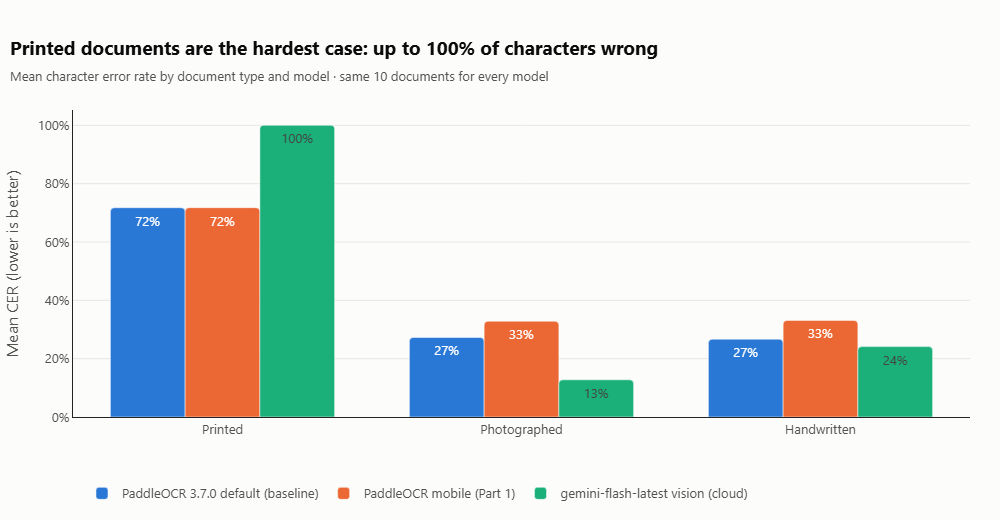

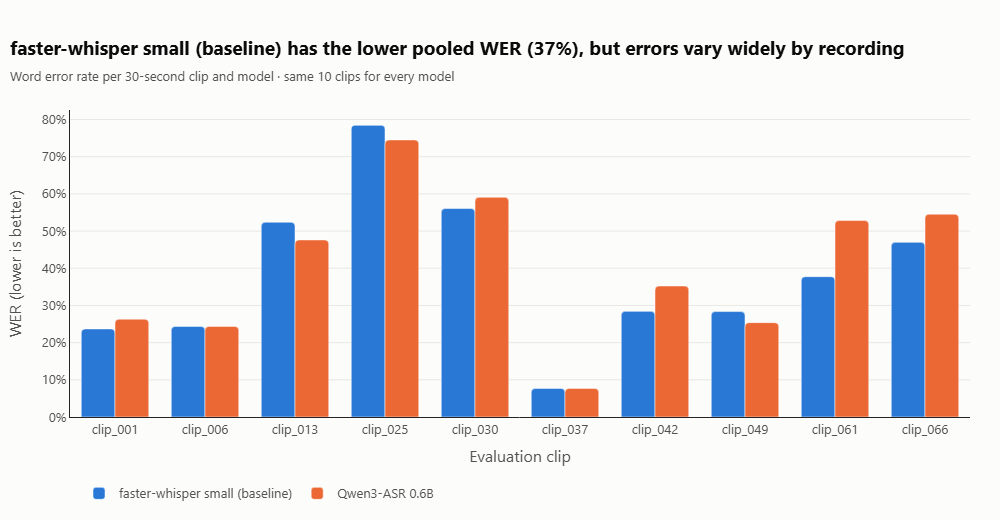

In [21]:
import plotly.express as px
import plotly.io as pio

# Static PNG copies make the charts visible on GitHub; fall back to interactive-only if export fails.
try:
    pio.to_image(px.bar(x=[1], y=[1]), format="png")
    pio.renderers.default = "vscode+png"
except Exception:
    pio.renderers.default = "vscode"

ETIQUETAS_TIPO = {"impreso": "Printed", "foto": "Photographed", "manuscrito": "Handwritten"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
TINTA, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"


def estilo(fig, titulo, subtitulo):
    # Same visual identity as Part 1: bold analytical headline, grey subtitle, light grid.
    fig.update_layout(
        template="simple_white",
        title=dict(text=f"<b>{titulo}</b>", x=0.01, xanchor="left", font=dict(size=19, color=TINTA),
                   subtitle=dict(text=subtitulo, font=dict(size=13, color=GRIS))),
        font=dict(family="Inter, Segoe UI, Arial", size=13, color=GRIS),
        paper_bgcolor=FONDO, plot_bgcolor=FONDO, margin=dict(l=70, r=30, t=110, b=80),
        bargap=0.25, barcornerradius=4, width=1000, height=520,
        legend=dict(orientation="h", y=-0.2, x=0.01, title_text=""),
        hoverlabel=dict(bgcolor="white", font_size=13, font_color=TINTA),
    )
    fig.update_yaxes(showgrid=True, gridcolor=REJILLA, zeroline=False, ticks="")
    fig.update_xaxes(showgrid=False, ticks="")
    return fig


tabla = eval_ocr.assign(Type=eval_ocr["tipo"].map(ETIQUETAS_TIPO))
tabla = tabla.groupby(["Type", "modelo"], as_index=False)["cer"].mean()
peor = tabla.loc[tabla["cer"].idxmax()]
fig = px.bar(tabla, x="Type", y="cer", color="modelo", barmode="group", text_auto=".0%",
             category_orders={"Type": list(ETIQUETAS_TIPO.values())}, color_discrete_sequence=SERIES)
fig.update_layout(xaxis_title="", yaxis_title="Mean CER (lower is better)", yaxis_tickformat=".0%")
estilo(fig, f"{peor['Type']} documents are the hardest case: up to {peor['cer']:.0%} of characters wrong",
       "Mean character error rate by document type and model · same 10 documents for every model")
fig.show()

mejor_asr = comparativa[comparativa["metrica"] == "WER"].sort_values("valor").iloc[0]
fig = px.bar(eval_asr, x="id", y="wer", color="modelo", barmode="group", color_discrete_sequence=SERIES,
             hover_data={"entrevista": True, "rtf": ":.2f"})
fig.update_layout(xaxis_title="Evaluation clip", yaxis_title="WER (lower is better)", yaxis_tickformat=".0%")
estilo(fig, f"{mejor_asr['modelo']} has the lower pooled WER ({mejor_asr['valor']:.0%}), "
            "but errors vary widely by recording",
       "Word error rate per 30-second clip and model · same 10 clips for every model")
fig.show()

## 7. Structured extraction with an LLM

Each pseudonymized text in the corpus (25 documents and 70 clips) is sent to Gemini with a fixed prompt that requests a JSON object. The prompt asks for `modalidad`, `tema` and `resumen` in every case; for documents, `emisor`, `fecha` and `monto` only if they appear; for audio, `citas_clave` and `numero_hablantes` only when the text supports them. Missing fields must be `null`, and the model is told not to invent information. Very long printed pages are truncated to their first 6,000 characters. Results are written to `datos/extraccion_llm.csv` as they arrive, so an interrupted run can resume without repeating calls.

In [22]:
# A lighter model for the 95 extraction calls: the default flash model takes over a minute per request.
for candidato in ["gemini-flash-lite-latest", "gemini-2.5-flash-lite", MODELO_GEMINI]:
    try:
        cliente.models.generate_content(model=candidato, contents="Reply with OK.")
        MODELO_LLM = candidato
        break
    except Exception as error:
        print(candidato, "not available:", type(error).__name__)
print("LLM for structured extraction:", MODELO_LLM)

PROMPT_LLM = '''You are cataloguing a Peruvian archive of documents and interview recordings.
The text below was produced automatically (OCR or speech recognition), so it may contain errors.
Labels such as [PERSONA_3], [DNI] or [TELEFONO] replace personal data; keep them as they are.

Return ONLY a JSON object with these keys:
- "modalidad": "{modalidad}"
- "tema": the topic, in Spanish, in at most 8 words
- "resumen": a one-sentence summary in Spanish, at most 35 words
{campos_extra}
Use null for every field that cannot be supported by the text. Never invent information.

TEXT:
{texto}'''

EXTRA_DOC = ('- "emisor": the institution, business or person that issues the document, or null\n'
             '- "fecha": a date written in the document, as written, or null\n'
             '- "monto": amounts of money or prices written in the document, as written, or null')
EXTRA_AUDIO = ('- "citas_clave": a list of up to 2 short literal quotes copied from the text, or null\n'
               '- "numero_hablantes": the number of distinct [HABLANTE_n] labels, or null if there are none')

registros = ([{"id": r["id"], "modalidad": "documento", "texto": r["texto_ocr"]} for _, r in documentos.iterrows()]
             + [{"id": r["id"], "modalidad": "audio", "texto": r["texto_asr"]} for _, r in transcripciones.iterrows()])

archivo_llm = DATOS / "extraccion_llm.csv"
hechos = pd.read_csv(archivo_llm, keep_default_na=False) if archivo_llm.exists() else pd.DataFrame()
filas_llm = hechos.to_dict("records")
ya_hechos = set(hechos["id"]) if not hechos.empty else set()

configuracion = types.GenerateContentConfig(response_mime_type="application/json", temperature=0)
for registro in registros:
    if registro["id"] in ya_hechos:
        continue
    prompt = PROMPT_LLM.format(modalidad=registro["modalidad"], texto=registro["texto"][:6000],
                               campos_extra=EXTRA_DOC if registro["modalidad"] == "documento" else EXTRA_AUDIO)
    respuesta = con_reintentos(lambda: cliente.models.generate_content(
        model=MODELO_LLM, contents=prompt, config=configuracion))
    try:
        campos = json.loads(respuesta.text)
    except (TypeError, ValueError):
        campos = {"error": "invalid JSON", "respuesta": respuesta.text}
    filas_llm.append({"id": registro["id"], "modalidad": registro["modalidad"],
                      "campos_json": json.dumps(campos, ensure_ascii=False),
                      "modelo_llm": MODELO_LLM, "fecha": date.today().isoformat()})
    pd.DataFrame(filas_llm).to_csv(archivo_llm, index=False, encoding="utf-8")
    print(registro["id"], "→", campos.get("tema") if isinstance(campos, dict) else campos)
    time.sleep(4.5)  # stay below the free-tier request limit

extraccion = pd.read_csv(archivo_llm, keep_default_na=False)
print(f"\n{len(extraccion)} extractions saved in {archivo_llm}")
extraccion.head()

LLM for structured extraction: gemini-flash-lite-latest

95 extractions saved in datos\extraccion_llm.csv


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Sumario de...",gemini-flash-lite-latest,2026-10-25
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Resolución...",gemini-flash-lite-latest,2026-10-25
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Expropiaci...",gemini-flash-lite-latest,2026-10-25
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Autorizaci...",gemini-flash-lite-latest,2026-10-25
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Solicitud ...",gemini-flash-lite-latest,2026-10-25


### Human audit of 20 random extractions

Ten documents and ten clips are drawn at random with a fixed seed. An extraction counts as **completely correct** only if all of the following hold:

1. `tema` and `resumen` are faithful to the source text.
2. Every non-null field is supported by the text, with no invented dates, issuers, amounts or quotes.
3. Fields that clearly appear in the text are not left as `null`.
4. Quotes are literal, and `numero_hablantes` matches the speaker labels.

The next cell prints each source text next to its extraction. The verdict for each case (1 = correct, 0 = incorrect) and a short note are recorded in the cell after it.

In [23]:
auditoria = pd.concat([
    extraccion[extraccion["modalidad"] == "documento"].sample(10, random_state=2026),
    extraccion[extraccion["modalidad"] == "audio"].sample(10, random_state=2026),
])
textos_fuente = {r["id"]: r["texto"] for r in registros}
for _, fila in auditoria.iterrows():
    print("=" * 100)
    print(fila["id"], "|", fila["modalidad"])
    print("SOURCE:", textos_fuente[fila["id"]][:900])
    print("EXTRACTION:", json.dumps(json.loads(fila["campos_json"]), ensure_ascii=False, indent=1))

print("\nTemplate for the next cell:")
print("REVISION = {")
for id_ in auditoria["id"]:
    print(f'    "{id_}": (1, ""),')
print("}")

doc_004 | documento
SOURCE:  El Peruano / Sábado 24 de octubre de 2026 NORMAS LEGALES 51 SE RESUELVE: Final del Decreto Legislativo N° 1557, a efectos de formular y aprobar los valores arancelarios de terrenos que estarán Artículo 1.- Se autoriza el viaje, en comisión de vigentes para los años fiscales 2025 y 2026, el Ministerio servicios, de la señora [PERSONA_6], de Economía y Finanzas utilizará la metodología Especialista Legal IIl de la Dirección de Servicios al empleada por el Ministerio de Vivienda, Construcción y Inversionista de la Agencia de Promoción de la Inversión Saneamiento, aprobando una metodología propia para el Privada - PROINVERSIóN, a la ciudad de París, siguiente año fiscal; República Francesa, del 1 al 8 de noviembre de 2026, Que, mediante la Resolución Ministerial Nº 207-2026- para los fines expuestos en la parte considerativa de la EF/15, el Ministerio de Economía y Finanzas aprueba su prese
EXTRACTION: {
 "modalidad": "documento",
 "tema": "Autorización de viaj

In [24]:
# Verdict for each audited extraction: (1 = completely correct, 0 = incorrect, "note").
REVISION = {
    "doc_004": (1, "date and amount are present in the page"),
    "doc_016": (0, "issuer (Salinera de Maras) left as null although it is printed on the package"),
    "doc_019": (1, ""),
    "doc_017": (0, "issuer (San Fernando) missing and only one of the four prices extracted"),
    "doc_015": (1, "publisher (Fondo Editorial PUCP) appears on the cover"),
    "doc_025": (1, ""),
    "doc_005": (1, "issuer given as the gazette; the page does not state the issuing body explicitly"),
    "doc_009": (1, ""),
    "doc_011": (1, ""),
    "doc_018": (1, "restaurant name in cursive was missed by OCR, so null is consistent with the text"),
    "clip_011": (1, ""),
    "clip_070": (1, "faithful to the transcript; 'bien itinerante' is an ASR error for 'BIAM itinerante'"),
    "clip_049": (1, ""),
    "clip_072": (0, "quote is not literal ('tienen' instead of 'tenían')"),
    "clip_023": (1, ""),
    "clip_019": (1, ""),
    "clip_009": (1, ""),
    "clip_066": (1, ""),
    "clip_048": (1, ""),
    "clip_063": (1, ""),
}

auditoria_llm = auditoria[["id", "modalidad", "campos_json"]].copy()
auditoria_llm["correcta"] = auditoria_llm["id"].map(lambda i: REVISION[i][0])
auditoria_llm["nota"] = auditoria_llm["id"].map(lambda i: REVISION[i][1])
auditoria_llm.to_csv(DATOS / "auditoria_llm.csv", index=False, encoding="utf-8")

aciertos = int(auditoria_llm["correcta"].sum())
print(f"LLM–human agreement: {aciertos}/20 = {aciertos / 20:.0%}")
print(auditoria_llm.groupby("modalidad")["correcta"].agg(["sum", "count"]))
display(auditoria_llm.loc[auditoria_llm["correcta"] == 0, ["id", "modalidad", "nota"]])

LLM–human agreement: 17/20 = 85%
           sum  count
modalidad            
audio        9     10
documento    8     10


,id,modalidad,nota
15,doc_016,documento,issuer (Salinera de Maras) left as null althou...
16,doc_017,documento,issuer (San Fernando) missing and only one of ...
94,clip_072,audio,quote is not literal ('tienen' instead of 'ten...


## 8. Export for the dashboard, and an authorized audio example

The evaluation tables are saved for the dashboard. Three photographs with no personal data are resized and copied to `datos/ejemplos/`. Re-saving the images also removes their EXIF metadata, including any GPS location. If a short self-recorded clip is available (`datos/ejemplos/demo_voz.*`), it is transcribed with the baseline model so that the dashboard can play an authorized example.

In [25]:
from PIL import Image, ImageOps

eval_ocr.to_csv(DATOS / "evaluacion_ocr.csv", index=False, encoding="utf-8")
eval_asr.to_csv(DATOS / "evaluacion_asr.csv", index=False, encoding="utf-8")
comparativa.to_csv(DATOS / "comparativa.csv", index=False, encoding="utf-8")

# Publishable photographs: public signage and a menu board, with no personal data.
for id_ in ["doc_012", "doc_013", "doc_018"]:
    ruta = Path(documentos.set_index("id").loc[id_, "archivo"])
    imagen = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    imagen.thumbnail((1200, 1200))
    imagen.save(EJEMPLOS / f"{id_}.jpg", quality=85)  # saved without EXIF metadata

demo = next(iter(sorted(EJEMPLOS.glob("demo_voz.*"))), None)
if demo is not None and demo.suffix != ".txt":
    from faster_whisper import WhisperModel
    segs, _ = WhisperModel("small", device="cpu", compute_type="int8").transcribe(
        voz.cargar_audio(demo), language="es", beam_size=5, vad_filter=True)
    texto_demo = " ".join(s.text.strip() for s in segs)
    (EJEMPLOS / "demo_voz.txt").write_text(texto_demo, encoding="utf-8")
    print("Authorized example transcribed:", texto_demo)

print(sorted(p.name for p in EJEMPLOS.iterdir()))

Authorized example transcribed: Este audio es un ejemplo autorizado del proyecto Voces y Documentos Peruanos. La pregunta que guía el trabajo es si es posible convertir documentos escaneados y entrevistas grabadas en un archivo de texto estructurado y buscable. Para responderla se construyó un corpus de 25 documentos peruanos entre impresos, fotografías y manuscritos y 35 minutos de entrevistas. El texto se extrajo con modelos abiertos, Paddle or Sear para las imágenes y Whisper para el audio. Luego, los datos personales fueron seodominizados y la calidad de cada modelo se evalvó frente a transcripciones manuales mediante las tasas de error por carácter y por palabras.
['demo_voz.m4a.ogg', 'demo_voz.txt', 'doc_012.jpg', 'doc_013.jpg', 'doc_018.jpg']


## 9. Comparison, difficult cases and decision

### 9.1 Comparative results

| Modality | Model | Pooled error | Mean time per file | RTF | Execution |
|---|---|---|---|---|---|
| Documents | PaddleOCR 3.7 default (baseline) | CER 0.525 | 130.1 s | — | local CPU |
| Documents | PaddleOCR PP-OCRv5 mobile (Part 1) | CER 0.540 | 33.6 s | — | local CPU |
| Documents | Gemini vision (`gemini-flash-latest`) | CER 0.637 | 119.1 s | — | cloud API |
| Audio | faster-whisper `small` (baseline) | WER 0.372 | 44.8 s | 1.49 | local CPU |
| Audio | Qwen3-ASR 0.6B | WER 0.393 | 133.3 s | 4.44 | local CPU |

Both metrics derive from the Levenshtein edit distance (Levenshtein, 1966), computed at the character level (CER) and at the word level (WER). They should therefore be read as measures of the effort required to turn the automatic output into the reference transcription, rather than as direct measures of comprehension.

### 9.2 Documents: performance by type

The printed page constitutes the most demanding case for every model. Both PaddleOCR configurations obtain a CER of 0.72 on it, a value that appears paradoxical given the typographic clarity of the official gazette. The explanation lies in the layout rather than in character recognition: the page is organised in three dense columns, and the detection stage of PP-OCR (Du et al., 2020) returns text lines in a top-to-bottom order that interleaves fragments from different columns. Consequently, many correctly recognised words appear in a different sequence from the reference, and an order-sensitive metric penalises this displacement heavily. The cloud vision model, by contrast, returned no text whatsoever for this page (0 characters; CER = 1.00). This outcome, plausibly attributable to the provider's restrictions on reproducing long passages verbatim, shows that a general-purpose model may fail silently on the very documents that institutional archives contain most frequently.

On photographed documents, the relationship is reversed. The vision model attains a mean CER of 0.13, compared with 0.27 for the default PaddleOCR, which suggests greater robustness to perspective distortion, uneven lighting and stylised commercial typography. Handwriting, in turn, remains the most persistent difficulty for all systems (CER between 0.24 and 0.33), with only a modest advantage for the cloud model. Finally, the comparison between the two local configurations makes the trade-off between accuracy and cost explicit: the default models reduce the CER on photographs and manuscripts by about six percentage points, yet they are approximately four times slower than the mobile models.

### 9.3 Audio: performance by recording condition

Both recognisers achieve comparable accuracy (WER 0.37 for faster-whisper and 0.39 for Qwen3-ASR), and neither dominates across all clips. The variation between recordings, however, is far greater than the variation between models: the WER ranges from 0.08 on a clear monologue (`clip_037`) to 0.75–0.78 on interview 3 (`clip_025`), whose deficient sound quality also led the voice activity detector to discard two clips as silent. These results suggest that, under realistic fieldwork conditions, recording quality is a more decisive factor than the choice between models of similar size, which is consistent with the robustness-oriented design of Whisper (Radford et al., 2023). In addition, domain-specific acronyms constitute a systematic source of error: *BIAM* was transcribed as *bien*, *VIAM* or *VIP*. The optional analysis of Huaylas Quechua with MMS was not undertaken.

### 9.4 Structured extraction

The LLM–human agreement reaches 17 of 20 audited cases (85 %; 8/10 documents and 9/10 clips). The errors are omissions, namely the issuer and several prices on commercial images, together with one quotation that is not literal; no fabricated date, issuer or amount was detected. Nevertheless, recognition errors propagate to the extracted fields, as illustrated by `clip_070`, where the transcription error *bien itinerante* is reproduced in the record. Accordingly, the quality of the structured layer is bounded by the quality of the preceding OCR and ASR stages.

### 9.5 Decision for a real setting

In light of accuracy, computational cost, latency and data protection, the following configuration is recommended:

- **Audio: faster-whisper `small`.** It combines the lowest pooled WER with a processing speed three times higher than that of Qwen3-ASR on CPU, an MIT licence, and fully local execution, which is a necessary condition for confidential interviews. The most promising improvements lie in better recording conditions and in supplying domain vocabulary (*BIAM*, *MINAM*, *CONAM*) as context. This strategy was deliberately not tested on the evaluation sample, in order to avoid tuning on the test data.
- **Documents: a hybrid strategy.** Local PaddleOCR should be used for printed and sensitive documents (default models when accuracy is the priority, mobile models when throughput is), complemented by a layout-analysis stage that restores the reading order of multi-column pages. A cloud vision model is justified only for photographs and manuscripts that are not confidential, and always subject to human review.
- **Structured extraction:** an 85 % agreement makes the LLM a useful aid for cataloguing, provided that fields with legal or economic implications, such as issuers and amounts, are verified by a person before publication.

These conclusions should be interpreted with caution, since the evaluation sample comprises only ten files per modality and a single printed page.



## 10. Final privacy check

A review of the exported files before publication revealed three kinds of residual identifiers: names printed in capital letters in the official gazette (the NER model is trained on mixed-case text and misses them), a name written in lower case by Qwen3-ASR, which the case-sensitive rule did not match, and a first name in a personal note. This final pass therefore (1) detects person names inside capitalised word sequences by applying the NER model to their title-cased form, and (2) replaces every known name regardless of case, except surnames that are also common Spanish words. It is applied to every published file. The metrics above were computed before this pass; replacing a few names does not change them materially.

In [26]:
EXTRA_NOMBRES = ["Julissa"]
PALABRAS_COMUNES = {"carrera", "alegría", "alegria", "cuña"}
for nombre in EXTRA_NOMBRES:
    seudonimos.setdefault(nombre, f"[PERSONA_{len(seudonimos) + 1}]")

# Names in capital letters: apply the NER model to the title-cased version of each capitalised sequence.
MAYUSCULAS = re.compile(r"\b(?:[A-ZÁÉÍÓÚÑÜ]{2,}\s+){1,4}[A-ZÁÉÍÓÚÑÜ]{2,}\b")
textos_revisar = list(documentos["texto_ocr"]) + list(documentos["texto_referencia"]) + list(eval_ocr["texto"])
for texto in textos_revisar:
    for tramo in {m.group(0) for m in MAYUSCULAS.finditer(texto)}:
        for ent in ner(tramo.title()):
            nombre = limpiar_nombre(ent["word"]).upper()
            if (ent["entity_group"] == "PER" and ent["score"] > 0.8
                    and len(nombre.split()) >= 2 and nombre in tramo):
                seudonimos.setdefault(nombre, f"[PERSONA_{len(seudonimos) + 1}]")


def seudonimizar_final(texto: str) -> str:
    # Replace every known name regardless of case, except surnames that are also common words.
    for nombre in sorted(seudonimos, key=len, reverse=True):
        banderas = 0 if nombre.lower() in PALABRAS_COMUNES else re.IGNORECASE
        texto = re.sub(rf"\b{re.escape(nombre)}\b", seudonimos[nombre], texto, flags=banderas)
    for alias, patron in PATRONES.items():
        texto = re.sub(patron, alias, texto)
    return texto


ARCHIVOS_PUBLICADOS = {
    "documentos.csv": ["texto_ocr", "texto_referencia"],
    "transcripciones.csv": ["texto_asr", "texto_referencia"],
    "evaluacion_ocr.csv": ["texto"],
    "evaluacion_asr.csv": ["texto"],
    "extraccion_llm.csv": ["campos_json"],
    "auditoria_llm.csv": ["campos_json"],
}
for archivo, columnas in ARCHIVOS_PUBLICADOS.items():
    tabla = pd.read_csv(DATOS / archivo, keep_default_na=False)
    for columna in columnas:
        tabla[columna] = tabla[columna].map(seudonimizar_final)
    tabla.to_csv(DATOS / archivo, index=False, encoding="utf-8")
(RAW / "seudonimos.json").write_text(json.dumps(seudonimos, ensure_ascii=False, indent=1), encoding="utf-8")

# Verification: count remaining occurrences of known names in the published files (names are not printed).
restantes = 0
for archivo, columnas in ARCHIVOS_PUBLICADOS.items():
    tabla = pd.read_csv(DATOS / archivo, keep_default_na=False)
    for columna in columnas:
        for texto in tabla[columna]:
            for nombre in seudonimos:
                banderas = 0 if nombre.lower() in PALABRAS_COMUNES else re.IGNORECASE
                restantes += len(re.findall(rf"\b{re.escape(nombre)}\b", texto, flags=banderas))
print(f"Pseudonym table: {len(seudonimos)} names | remaining occurrences in published files: {restantes}")

Pseudonym table: 67 names | remaining occurrences in published files: 0


### References

- Du, Y., Li, C., Guo, R., Yin, X., Liu, W., Zhou, J., … Wang, H. (2020). PP-OCR: A practical ultra lightweight OCR system. *arXiv preprint arXiv:2009.09941*.
- Levenshtein, V. I. (1966). Binary codes capable of correcting deletions, insertions, and reversals. *Soviet Physics Doklady, 10*(8), 707–710.
- Radford, A., Kim, J. W., Xu, T., Brockman, G., McLeavey, C., & Sutskever, I. (2023). Robust speech recognition via large-scale weak supervision. *Proceedings of the 40th International Conference on Machine Learning*, 28492–28518.

### Use of AI assistance

An AI assistant (Claude, used through a chat interface and Claude Code) supported the development of this project, as permitted by the assignment. The complete interaction is documented in `evidencias_ia/`. Its contribution was limited to three areas:

- **Code drafting and debugging:** proposing the notebook code, adapting the Session 10 and 13 tools to the local environment, and diagnosing technical errors (for example, the oneDNN incompatibility on Windows and the NER token limit).
- **Academic writing in English:** drafting the explanatory Markdown cells, the README and the dashboard texts from the results obtained, which were then reviewed and adjusted.
- **Methodological guidance:** suggesting how to structure the corpus, the evaluation sample and the audit criteria in line with the assignment's requirements.

The research decisions and every step that determines the validity of the results were carried out by the student: collecting the corpus and securing informed consent, transcribing the 20 references manually, reviewing the pseudonymization, auditing the LLM extractions, and verifying the final outputs. The Gemini model used in Sections 4 and 7 is a component of the pipeline under evaluation, not a development assistant.